# Fase 5 — O Agente Integrador: Verificação de Respostas e Avaliação com LangSmith

Tudo converge num **agente único**: `create_openai_tools_agent` + `AgentExecutor` com todas as ferramentas (RAG, SQL, APIs, hardcoded, semânticas e ação), `RunnableWithMessageHistory` com histórico persistente, memória de longo prazo, reconhecimento de intenção e uma **camada de verificação** que faz parte do próprio agente: cada resposta é checada contra as evidências e, se reprovada, corrigida antes de chegar ao usuário. Em seguida, o agente é avaliado como sistema no LangSmith (qualidade e trajetória), em dois experimentos comparados.

In [1]:
import sys, pathlib, json, sqlite3, warnings, shutil
import pandas as pd
RAIZ = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(RAIZ))
from fabrica_agentica.config import descrever_ambiente, CAMINHO_BANCO
print(descrever_ambiente())
pd.set_option("display.max_colwidth", 110)

Provedor de LLM : anthropic
APIs externas   : rede (ao vivo)
Embeddings      : sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Modelo NLI      : MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7
LangSmith       : ligado
Repositório GH  : DriccoC/fabrica-agentica-sandbox


## 1. Mecanismo de verificação de respostas (V&V)

```
resposta do agente ──► 1. extração de afirmações (LLM, saída estruturada: "fato" ou "conclusão")
evidências da sessão ─┤ 2. fact-check determinístico: os números citados aparecem nas evidências?
(saídas das ferramentas,  3. NLI (mDeBERTa-v3 XNLI, local) nos FATOS: sustentação / contradição / neutralidade,
 regras procedurais,         frase a frase contra as evidências mais parecidas
 memórias)              4. coerência lógica (LLM juiz): contradição premissa-conclusão, erro de cálculo,
                           violação de escopo, afirmação sem evidência
                        ──► aprovado?  não ──► correção com o feedback ──► nova verificação
```

**Decisões de projeto (tomadas a partir de falhas observadas):**

- **Evidência = tudo o que o agente observou na sessão** (não só o turno): na simulação "e se tirarmos o Bruno?", o plano de 11 pontos vem do turno anterior; com evidência só do turno, o verificador o tratava como "sem fonte" e a correção apagava o plano.
- **NLI só para fatos; conclusões vão ao juiz.** Modelos NLI checam bem fatos enunciados, mas não fazem aritmética: "faltam 2 pontos" (11 − 9) aparece para eles como contradição. Conclusões derivadas (cabe/não cabe, faltam, sobram) são avaliadas pelo juiz de coerência.
- **Severidade:** só contradição NLI forte (≥ 0,80) em fato, contradição premissa-conclusão ou erro de cálculo **reprovam**; detalhes secundários sem fonte viram **alertas** (reprovar por eles fazia a correção cortar informação correta).
- **Modelo NLI:** o MiniLMv2 pequeno, testado primeiro, deixou passar "saldo de 25 pontos" e "a authlib 1.3.0 pode ser usada"; o mDeBERTa-v3 (base) detecta a primeira com 0,97 de contradição. A comparação abaixo roda os dois.

In [2]:
from fabrica_agentica.verificacao.verificador import nli, _modelo_nli
from transformers import pipeline

pequeno = pipeline("text-classification", model="MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli", top_k=None)
premissa = ("A capacidade bruta da sprint 13 é de 25.65 pontos. A capacidade líquida da sprint 13 é de 20 pontos. "
            "O saldo disponível da sprint 13 é de 9 pontos. A versão 1.3.0 de authlib tem 34 vulnerabilidades conhecidas.")
hipoteses = ["A sprint 13 tem saldo de 25 pontos.", "A authlib 1.3.0 não tem vulnerabilidades.",
             "O saldo disponível da sprint 13 é de 9 pontos.", "Sem o Bruno, faltam 2 pontos para o plano caber."]
linhas = []
for h in hipoteses:
    p = {d["label"]: round(d["score"], 3) for d in pequeno({"text": premissa, "text_pair": h})}
    g = nli(premissa, h)
    linhas.append({"hipótese": h, "MiniLMv2 (contradição)": p.get("contradiction"), "MiniLMv2 (sustentação)": p.get("entailment"),
                   "mDeBERTa (contradição)": round(g["contradiction"], 3), "mDeBERTa (sustentação)": round(g["entailment"], 3)})
pd.DataFrame(linhas)

W1109 09:54:14.195000 74321 .venv/lib/python3.12/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

/Users/adrianocarvalho/Documents/_MBA/Agentes_Cognitivos/projeto_fabrica_agentica/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

,hipótese,MiniLMv2 (contradição),MiniLMv2 (sustentação),mDeBERTa (contradição),mDeBERTa (sustentação)
0,A sprint 13 tem saldo de 25 pontos.,0.008,0.984,0.995,0.002
1,A authlib 1.3.0 não tem vulnerabilidades.,0.994,0.002,0.999,0.000
2,O saldo disponível da sprint 13 é de 9 pontos.,0.037,0.894,0.001,0.998
3,"Sem o Bruno, faltam 2 pontos para o plano caber.",0.841,0.005,0.089,0.846


A última linha mostra o limite dos dois modelos: a conclusão aritmética correta "faltam 2 pontos" é lida como contradição — por isso ela é delegada ao juiz de coerência.

### 1.1 Testes do verificador: resposta correta, resposta forjada e a contradição REAL da Fase 3

O terceiro caso é o texto que o próprio agente produziu na Fase 3 (simulação sem o Bruno): começa com "sim, o plano ainda cabe" e termina com "faltam 2 pontos".

In [3]:
from fabrica_agentica.ferramentas.catalogo import calcular_capacidade_sprint, consultar_vulnerabilidades
from fabrica_agentica.verificacao.evidencias import verbalizar, regras_procedurais
from fabrica_agentica.verificacao.verificador import verificar

evidencias = verbalizar("calcular_capacidade_sprint", calcular_capacidade_sprint.invoke({"projeto": "Portal", "remover_integrantes": ["Bruno"]}))
evidencias += ["O plano proposto 'Login com Google no Portal' tem 3 histórias e soma 11 pontos.",
               "As histórias do plano proposto ainda não estão registradas e não fazem parte dos pontos já comprometidos."]
evidencias += verbalizar("consultar_vulnerabilidades", consultar_vulnerabilidades.invoke({"pacote": "authlib", "versao": "1.3.0"}))[:3]
evidencias += regras_procedurais()

casos = {
    "correta": "Sem o Bruno, o plano não cabe: o saldo da sprint 13 cai para 9 pontos e o plano soma 11 pontos, faltando 2 pontos. A capacidade líquida passa a 20 pontos.",
    "forjada (adversarial)": "A sprint 13 tem saldo de 25 pontos, então o plano de 11 pontos cabe com folga. A authlib 1.3.0 não tem vulnerabilidades e pode ser usada.",
    "real da Fase 3": "**Sim, o plano ainda cabe sem o Bruno.** O saldo cai de 14 para 9 pontos. O plano tem 11 pontos, mas desses, 11 já estão comprometidos na sprint. Sem o Bruno, faltam 2 pontos para o plano caber.",
}
for nome, texto in casos.items():
    r = verificar(texto, evidencias)
    print(f"\n=== {nome}: {r.resumo()}")
    for a in r.afirmacoes:
        print(f"   [{a.tipo:9}] {a.nli:17} contradição={a.prob_contradicao:<5} | {a.texto[:95]}")
    print(f"   coerência: {r.coerencia.veredito} | {r.coerencia.falhas}\n   {r.coerencia.justificativa[:300]}")
    for m in r.motivos:
        print("   ❌", m[:200])
    for m in r.alertas:
        print("   ⚠️", m[:200])

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


=== correta: APROVADA | 5 afirmações: 3 sustentadas, 0 contraditas | coerência: ok
   [conclusao] conclusão (juiz)  contradição=0.0   | Sem o Bruno, o plano não cabe na sprint 13.
   [fato     ] sustentada        contradição=0.0   | O saldo da sprint 13 cai para 9 pontos sem o Bruno.
   [fato     ] sustentada        contradição=0.0   | O plano da sprint 13 soma 11 pontos.
   [conclusao] conclusão (juiz)  contradição=0.0   | Sem o Bruno, o plano da sprint 13 faltam 2 pontos.
   [fato     ] sustentada        contradição=0.0   | Sem o Bruno, a capacidade líquida da sprint 13 passa a 20 pontos.
   coerência: APOIA | ['nenhuma']
   A resposta está de acordo com as evidências: na simulação sem Bruno o saldo é de 9 pontos, o plano soma 11 e a capacidade líquida é de 20 pontos. A conta 11 - 9 = 2 pontos faltantes está correta, e a conclusão de que o plano não cabe decorre das premissas. Não há contradição interna, erro de cálculo



=== forjada (adversarial): REPROVADA | 4 afirmações: 0 sustentadas, 1 contraditas | coerência: contradicao_premissa_conclusao, erro_de_calculo
   [fato     ] neutra            contradição=0.531 | A sprint 13 tem saldo de 25 pontos.
   [conclusao] conclusão (juiz)  contradição=0.0   | O plano de 11 pontos cabe com folga na sprint 13.
   [fato     ] contradição       contradição=0.997 | A authlib 1.3.0 não tem vulnerabilidades.
   [conclusao] conclusão (juiz)  contradição=0.0   | A authlib 1.3.0 pode ser usada.
   coerência: REFUTA | ['contradicao_premissa_conclusao', 'erro_de_calculo']
   A resposta afirma 'saldo de 25 pontos', mas as evidências indicam saldo de 9 pontos (capacidade líquida 20 menos 11 comprometidos); 25.65 é a capacidade bruta. Com saldo de 9, o plano de 11 pontos NÃO cabe, contrariando 'cabe com folga'. Também diz que a authlib 1.3.0 'não tem vulnerabilidades e pod
   ❌ Contradição com as evidências (NLI 1.00): A authlib 1.3.0 não tem vulnerabilidades.
   ❌ Incoerênc


=== real da Fase 3: REPROVADA | 4 afirmações: 0 sustentadas, 0 contraditas | coerência: contradicao_premissa_conclusao, afirmacao_sem_evidencia, erro_de_calculo
   [conclusao] conclusão (juiz)  contradição=0.0   | O plano ainda cabe sem o Bruno.
   [fato     ] neutra            contradição=0.02  | O saldo cai de 14 para 9 pontos quando o Bruno sai.
   [fato     ] neutra            contradição=0.002 | O plano tem 11 pontos, e desses 11 pontos já estão comprometidos na sprint.
   [conclusao] conclusão (juiz)  contradição=0.0   | Sem o Bruno, faltam 2 pontos para o plano caber.
   coerência: REFUTA | ['contradicao_premissa_conclusao', 'afirmacao_sem_evidencia', 'erro_de_calculo']
   A resposta começa com 'o plano ainda cabe sem o Bruno' e termina com 'faltam 2 pontos para o plano caber', o que é uma contradição interna. Pelas evidências, o saldo é 9 pontos (capacidade líquida 20 menos 11 já comprometidos) e o plano soma 11, então não cabe: faltam 2 pontos. A conclusão inicial e
   ❌ Inco

## 2. O agente único integrador: `create_openai_tools_agent` + `AgentExecutor` + `RunnableWithMessageHistory`

In [4]:
import inspect
from fabrica_agentica.agentes import integrador
print(inspect.getsource(integrador.criar_executor_com_historico))

def criar_executor_com_historico(janela: int = 6) -> RunnableWithMessageHistory:
    """AgentExecutor + RunnableWithMessageHistory (histórico SQLite, janela + resumo)."""
    executor = criar_executor(com_memoria_longa=True)
    cadeia = (
        RunnablePassthrough.assign(chat_history=lambda x: comprimir(x.get("chat_history", []), x["sessao_id"], janela))
        | executor
        | RunnableLambda(lambda r: {**r, "output": texto_de(r["output"])})
    )
    return RunnableWithMessageHistory(
        cadeia,
        get_session_history=lambda sessao_id: HistoricoSQLite(sessao_id),
        input_messages_key="input",
        history_messages_key="chat_history",
        output_messages_key="output",
    )



Uma sessão completa de uso, com ferramentas de categorias diferentes (cálculo, SQL, RAG, APIs externas, semântica e ação). O banco de backlog é copiado antes e restaurado no fim, porque a aprovação grava de verdade.

In [5]:
from fabrica_agentica.agentes.integrador import TechLeadAgentico
from fabrica_agentica.observabilidade.callbacks import RegistroExecucao
from fabrica_agentica.memoria.longo_prazo import MemoriaLongoPrazo

copia_banco = RAIZ / "logs" / "backlog_antes_da_fase5.db"
shutil.copy(CAMINHO_BANCO, copia_banco)
MemoriaLongoPrazo(escopo="adriano-f5").esquecer_tudo()
log = RegistroExecucao(sessao="fase5")
agente = TechLeadAgentico(usuario="adriano-f5", callbacks=[log])
print("Sessão:", agente.sessao_id)

def mostrar(t):
    print(f"\n🧑 {t.mensagem}\n   intenção: {t.intencao} | estado: {t.estado_sessao} | {t.duracao_s}s")
    if t.trajetoria:
        print("   trajetória:", [f"{p['ferramenta']} ({p['tipo']})" for p in t.trajetoria])
    if t.verificacao_rascunho:
        print("   verificação do rascunho:", t.verificacao_rascunho.resumo())
        for m in t.verificacao_rascunho.motivos:
            print("     ❌", m[:220])
    if t.corrigida:
        print("   ↻ resposta CORRIGIDA; verificação final:", t.verificacao.resumo())
    print(f"🤖 {t.resposta}")

t1 = agente.conversar("Quero login com Google no projeto Portal na próxima sprint.")
mostrar(t1)

Sessão: adriano-f5-84f9fd


/Users/adrianocarvalho/Documents/_MBA/Agentes_Cognitivos/projeto_fabrica_agentica/fabrica_agentica/agentes/integrador.py:116: LangChainDeprecationWarning: RunnableWithMessageHistory is deprecated. Use LangGraph's built-in persistence instead.
  self.agente = criar_executor_com_historico()



🧑 Quero login com Google no projeto Portal na próxima sprint.
   intenção: planejar_demanda | estado: {'projeto': 'Portal', 'pacote': 'authlib'} | 38.9s
   trajetória: ['calcular_capacidade_sprint (hardcoded)', 'buscar_manual_engenharia (RAG (FAISS))', 'buscar_issues_github (API externa)', 'consultar_pypi (API externa)', 'buscar_manual_engenharia (RAG (FAISS))', 'consultar_vulnerabilidades (API externa)', 'decompor_demanda (semântica)']
   verificação do rascunho: APROVADA | 10 afirmações: 2 sustentadas, 0 contraditas | coerência: ok
🤖 **Conclusão:** o login com Google cabe na sprint 13 do Portal. O plano tem 3 histórias e 13 pontos, para um saldo de 14, e sobra 1 ponto. Já existem as issues #1, #2 e #3 no GitHub com o mesmo escopo, então confirme com você antes de registrar para não duplicar.

**Capacidade** (calcular_capacidade_sprint, MAN-06 §3)
- A sprint 13 vai de 09/11 a 20/11/2026 e tem 9 dias úteis. O dia 20/11 é feriado (Consciência Negra, BrasilAPI).
- A capacidade líquida é

In [6]:
t2 = agente.conversar("E se tirarmos o Bruno da sprint, o plano ainda cabe?")
mostrar(t2)
if t2.corrigida:
    print("\n--- RASCUNHO REPROVADO (antes da correção) ---\n", t2.resposta_rascunho)


🧑 E se tirarmos o Bruno da sprint, o plano ainda cabe?
   intenção: consultar_backlog | estado: {'projeto': 'Portal', 'pacote': 'authlib', 'sprint': 13, 'pessoa': 'Bruno'} | 18.5s
   trajetória: ['calcular_capacidade_sprint (hardcoded)']
   verificação do rascunho: APROVADA | 10 afirmações: 0 sustentadas, 1 contraditas | coerência: ok
🤖 **Conclusão:** sem o Bruno, o plano completo de 13 pontos não cabe na sprint 13. O saldo cai para 9 pontos e faltam 4.

**Capacidade sem o Bruno** (calcular_capacidade_sprint, MAN-06 §3)
- A capacidade líquida passa de 25 para 20 pontos, já com a reserva de 20% para defeitos (5,13 pontos).
- Os pontos comprometidos continuam em 11, então o saldo é de 9 pontos (antes era 14).
- A capacidade bruta é de 25,65 pontos, somando Ana, Carla, Diego e Eduarda.

**O que cabe com 9 pontos**
- A história 1 (login com Google via Keycloak, 5 pontos) e a história 2 (vínculo de conta e bloqueio de pessoa jurídica, 3 pontos) somam 8 pontos. Sobra 1 ponto.
- A história 3

In [7]:
t3 = agente.conversar("Ok, mantemos o Bruno. Registre o plano na sprint 13 e abra as issues.")
mostrar(t3)
print("\nPendências aguardando aprovação humana:", json.dumps(t3.pendencias, ensure_ascii=False, indent=1)[:900])


🧑 Ok, mantemos o Bruno. Registre o plano na sprint 13 e abra as issues.
   intenção: planejar_demanda | estado: {'projeto': 'Portal', 'pacote': 'authlib', 'sprint': 13, 'pessoa': 'Bruno'} | 39.2s
   trajetória: ['propor_registro_backlog (ação (aprovação humana))']
   verificação do rascunho: REPROVADA | 10 afirmações: 2 sustentadas, 2 contraditas | coerência: ok
     ❌ Contradição com as evidências (NLI 0.82): A pendência 6acebf68 é do projeto Portal, sprint 13, épico "Login social com Google no Portal".
     ❌ Contradição com as evidências (NLI 0.98): Falta definir a lista de operações sensíveis para a história de MFA do épico "Login social com Google no Portal".
   ↻ resposta CORRIGIDA; verificação final: REPROVADA | 10 afirmações: 1 sustentadas, 1 contraditas | coerência: ok
🤖 **Conclusão:** a proposta de registro está pronta (pendência `6acebf68`), mas **nada foi gravado**. Ela só vira registro depois da sua confirmação na interface.

**O que a pendência contém**
- Projeto Portal,

### 2.1 Aprovação humana e execução da ação

Nada foi gravado até aqui. A aprovação (na interface, é um botão) executa a gravação no backlog e a abertura das issues. Neste notebook a escrita no GitHub fica em modo **simulado** de propósito, para não duplicar issues no repositório; as issues **reais** são abertas na sessão da interface Streamlit (capturas na seção 4) e no vídeo de demonstração.

In [8]:
import os
os.environ["GITHUB_ESCRITA_REAL"] = "0"  # neste notebook as issues são simuladas (ver texto acima)
conta = lambda: sqlite3.connect(CAMINHO_BANCO).execute("SELECT COUNT(*) FROM historias").fetchone()[0]
print("Histórias no backlog antes da aprovação:", conta())
if t3.pendencias:
    resultado = agente.aprovar(t3.pendencias[0], aprovado_por="Adriano (notebook)")
    print(json.dumps(resultado, ensure_ascii=False, indent=1, default=str)[:1500])
print("Histórias no backlog depois da aprovação:", conta())

Histórias no backlog antes da aprovação: 22
{
 "historias_criadas": [
  {
   "historia_id": 303,
   "titulo": "Como usuário pessoa física, quero entrar no Portal com minha conta Google, para acessar sem criar nova senha",
   "pontos": 5
  },
  {
   "historia_id": 304,
   "titulo": "Como usuário, quero vincular minha conta Google a uma conta interna com e-mail verificado, para garantir um login seguro e restrito a pessoa física",
   "pontos": 3
  },
  {
   "historia_id": 305,
   "titulo": "Como usuário autenticado por login social, quero que operações sensíveis exijam MFA, para proteger minha conta",
   "pontos": 5
  }
 ],
 "issues": [
  {
   "numero": 1001,
   "titulo": "Como usuário pessoa física, quero entrar no Portal com minha conta Google, para acessar sem criar nova senha",
   "estado": "open",
   "url": "(simulada) issue #1001",
   "corpo": "**Épico:** Login social com Google no Portal\n\n**Objetivo:** Permitir que pessoas físicas entrem no Portal com a conta Google, via Keycloa

### 2.2 Histórico persistente (`RunnableWithMessageHistory` + SQLite)

Um **novo objeto** de agente, com o mesmo `session_id`, continua a conversa: o histórico está no SQLite, não na memória do processo.

In [9]:
from fabrica_agentica.memoria.historico import HistoricoSQLite
print("Mensagens persistidas na sessão:", len(HistoricoSQLite(agente.sessao_id).messages))
agente_retomado = TechLeadAgentico(usuario="adriano-f5", sessao_id=agente.sessao_id, callbacks=[log])
mostrar(agente_retomado.conversar("Recapitule em 3 linhas o que decidimos nesta sessão e o total de pontos registrado."))

Mensagens persistidas na sessão: 6


/Users/adrianocarvalho/Documents/_MBA/Agentes_Cognitivos/projeto_fabrica_agentica/fabrica_agentica/agentes/integrador.py:116: LangChainDeprecationWarning: RunnableWithMessageHistory is deprecated. Use LangGraph's built-in persistence instead.
  self.agente = criar_executor_com_historico()



🧑 Recapitule em 3 linhas o que decidimos nesta sessão e o total de pontos registrado.
   intenção: consultar_backlog | estado: {} | 11.6s
🤖 1. **Escopo:** épico "Login social com Google no Portal" na sprint 13, com 3 histórias: login via Keycloak com PKCE (5 pontos), vínculo de conta e bloqueio de pessoa jurídica (3) e MFA em operações sensíveis (5). Mantemos o Bruno, então o saldo da sprint é de 14 pontos e sobra 1 (calcular_capacidade_sprint).
2. **Pontos:** o plano soma 13 pontos, mas **nenhum ponto está registrado ainda**. Os 13 estão na pendência `6acebf68`, que só vira registro depois da sua confirmação na interface.
3. **Em aberto:** as issues #1, #2 e #3 já existem e podem duplicar com as novas. Falta também definir a lista de operações sensíveis para o MFA e configurar o Google como IdP federado no Keycloak (MAN-05 CHK_028, MAN-07 CHK_039).


In [10]:
shutil.copy(copia_banco, CAMINHO_BANCO)  # restaura o backlog original (reprodutibilidade)
print("Backlog restaurado. Histórias:", conta())
resumo_log = log.resumo()
print(json.dumps({k: v for k, v in resumo_log.items() if k not in ("erros", "ferramentas")}, indent=1), "| ferramentas:", len(resumo_log["ferramentas"]), "| erros:", len(resumo_log["erros"]))

Backlog restaurado. Histórias: 22
{
 "chamadas_llm": 10,
 "tokens_entrada": 74162,
 "tokens_saida": 6749,
 "tempo_llm_s": 48.3,
 "tempo_ferramentas_s": 10.91
} | ferramentas: 9 | erros: 0


## 3. Versão LangGraph (base para a próxima disciplina)

O mesmo agente com `create_agent` (grafo LangGraph), checkpoints em SQLite por `thread_id` e **aprovação humana nativa** com `HumanInTheLoopMiddleware`: a ferramenta `registrar_no_backlog` grava de fato, mas o grafo **pausa** antes de executá-la e só continua com `Command(resume=...)`.

Para economizar chamadas, o planejamento completo (já demonstrado na seção 2) não é repetido: o pedido de registro vem direto, com a história definida.

In [11]:
shutil.copy(CAMINHO_BANCO, copia_banco)
agente_lg = TechLeadAgentico(usuario="adriano-f5-lg", motor="langgraph", callbacks=[log])
t_lg = agente_lg.conversar("Registre no backlog do Portal, sprint 13, a história 'Login com Google via OIDC' com 5 pontos e abra a issue.")
mostrar(t_lg)
estado = agente_lg.langgraph.grafo.get_state({"configurable": {"thread_id": agente_lg.sessao_id}})
print("\nO grafo está pausado antes de:", estado.next, "| interrupções:", len(estado.interrupts))
print("Requisição de aprovação:", json.dumps(t_lg.pendencias, ensure_ascii=False, default=str)[:700] if t_lg.pendencias else "(nenhuma)")


🧑 Registre no backlog do Portal, sprint 13, a história 'Login com Google via OIDC' com 5 pontos e abra a issue.
   intenção: planejar_demanda | estado: {'projeto': 'Portal', 'sprint': 13} | 22.9s
   trajetória: ['calcular_capacidade_sprint (hardcoded)', 'buscar_manual_engenharia (RAG (FAISS))', 'buscar_issues_github (API externa)', 'buscar_issues_github (API externa)']
   verificação do rascunho: APROVADA | 10 afirmações: 3 sustentadas, 0 contraditas | coerência: ok
🤖 **Recomendo não registrar ainda: já existem issues abertas para esse trabalho.** A capacidade da sprint comporta a história, mas o GitHub já tem um épico "Login social com Google no Portal" com três issues abertas. Se eu gravar agora, vou duplicar trabalho.

**Capacidade**
- Cabem 5 pontos na sprint 13 do Portal. O saldo é de 14 pontos, então restariam 9 (calcular_capacidade_sprint, MAN-06 §3).
- A capacidade líquida é de 25 pontos, com 11 já comprometidos.
- A sprint vai de 09/11 a 20/11/2026 e tem 9 dias úteis. O dia 2

O agente encontrou as issues #1 a #3, abertas pouco antes na sessão da interface (seção 4), e, em vez de duplicar trabalho, pediu uma decisão. Com a escolha da opção 3, o grafo chega à ferramenta de gravação e **pausa** à espera da aprovação humana:

In [ ]:
t_lg = agente_lg.conversar("Fico com a opção 3: registre só no backlog do Portal, sprint 13, a história 'Login com Google via OIDC' com 5 pontos, sem abrir issue.")
mostrar(t_lg)
estado = agente_lg.langgraph.grafo.get_state({"configurable": {"thread_id": agente_lg.sessao_id}})
print("\nO grafo está pausado antes de:", estado.next, "| interrupções:", len(estado.interrupts))
print("Requisição de aprovação:", json.dumps(t_lg.pendencias, ensure_ascii=False, default=str)[:700] if t_lg.pendencias else "(nenhuma)")

W1109 09:58:04.551000 76008 .venv/lib/python3.12/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]


🧑 Fico com a opção 3: registre só no backlog do Portal, sprint 13, a história 'Login com Google via OIDC' com 5 pontos, sem abrir issue.
   intenção: planejar_demanda | estado: {'projeto': 'Portal', 'sprint': 13} | 16.2s
🤖 

O grafo está pausado antes de: ('HumanInTheLoopMiddleware.after_model',) | interrupções: 1
Requisição de aprovação: [{"tipo": "langgraph_hitl", "requisicao": {"action_requests": [{"name": "registrar_no_backlog", "args": {"projeto": "Portal", "numero_sprint": 13, "abrir_issues": false, "plano": {"epico": "Login social com Google no Portal", "objetivo": "Permitir que pessoas físicas entrem no Portal com a conta Google, vinculada a uma conta interna, conforme MAN-05 e ADR-012.", "historias": [{"titulo": "Como pessoa física, quero fazer login com Google via OIDC, para acessar o Portal sem criar uma nova senha", "criterios_aceite": ["Dado que sou pessoa física com e-mail verificado, quando escolho 'Entrar com Google', então sou autenticado via Keycloak usando OIDC com 

In [12]:
if t_lg.pendencias:
    retomada = agente_lg.aprovar(t_lg.pendencias[0], aprovado_por="Adriano (notebook)")
    print("Ferramentas executadas após a aprovação:", [p["ferramenta"] for p in retomada["passos"]])
    print("🤖", retomada["resposta"][:1000])
print("Histórias no backlog:", conta())
shutil.copy(copia_banco, CAMINHO_BANCO)
print("Backlog restaurado:", conta())

Ferramentas executadas após a aprovação: ['registrar_no_backlog']
🤖 A história foi registrada no backlog do Portal, na sprint 13, e não abri nenhuma issue. A gravação foi aprovada por uma pessoa.

- **História:** nº 303, "Como pessoa física, quero fazer login com Google via OIDC, para acessar o Portal sem criar uma nova senha", com 5 pontos.
- **Saldo da sprint 13:** passa de 14 para 9 pontos (calcular_capacidade_sprint, MAN-06 §3).
- **Critérios de aceite:** escrevi quatro, em Gherkin.
  - Login via Keycloak com OIDC, código de autorização e PKCE (MAN-05, CHK_024).
  - Integração só com o Keycloak, sem ligar o Portal direto ao Google (MAN-07, ADR-012, CHK_039).
  - Vínculo obrigatório com conta interna e e-mail verificado (MAN-05, CHK_025).
  - Acesso negado a clientes B2B no login social (MAN-05, CHK_025).
- **Tarefas:** são cinco.
  - Configurar o Google como provedor federado no Keycloak.
  - Integrar o Portal ao Keycloak via OIDC com PKCE.
  - Implementar o vínculo com a conta int

## 4. Interface Streamlit

`streamlit run app.py` expõe o mesmo agente (seletor de motor: AgentExecutor ou LangGraph). Para cada resposta, a interface mostra a **trajetória** (ferramentas e tipos), o **relatório de verificação** (afirmações, NLI, coerência e, quando houve correção, o rascunho reprovado e os motivos) e as **memórias** usadas; pendências de registro aparecem com os botões **Aprovar e gravar** / **Rejeitar**. Capturas em `relatorio/capturas/`.

01_ferramentas_em_execucao.png


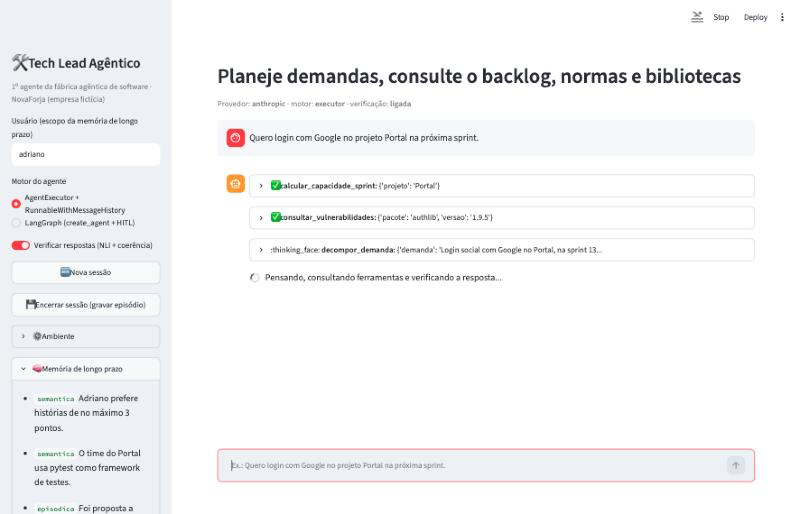

02_resposta_planejamento.png


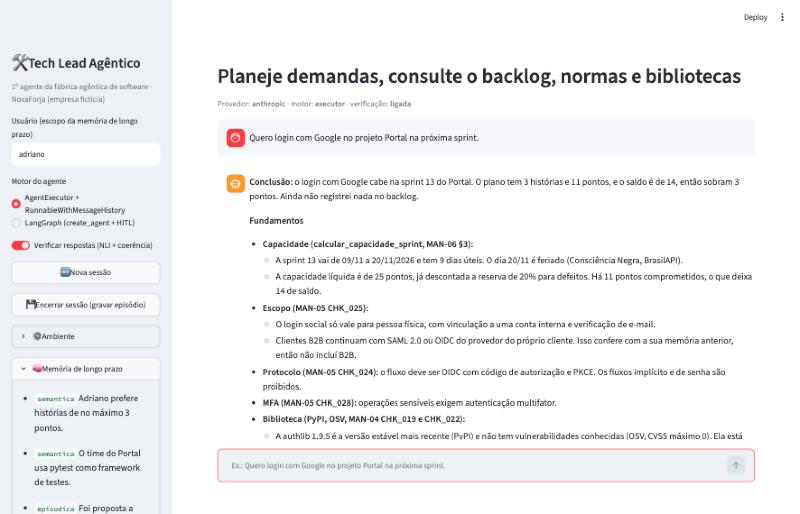

03_trajetoria.png


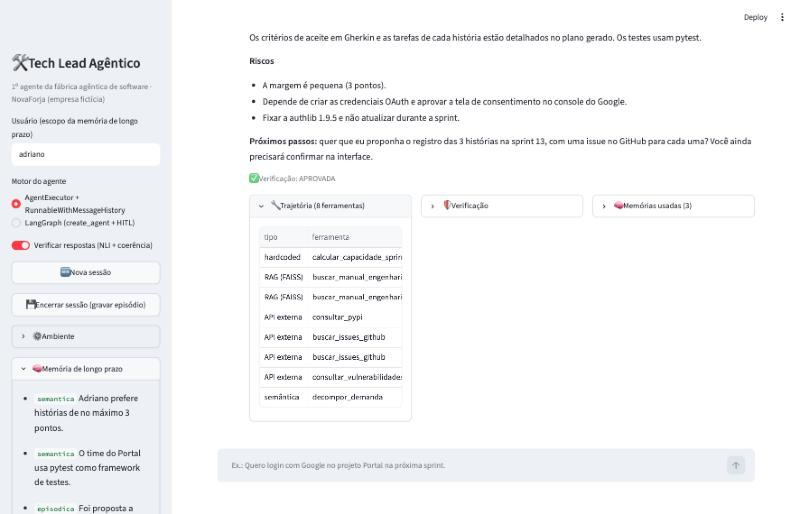

04_verificacao.png


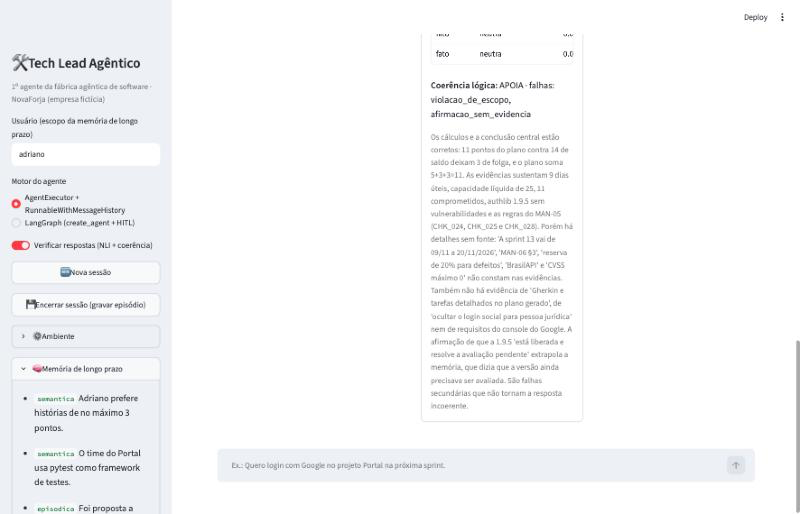

05_memoria_turno_bruno.png


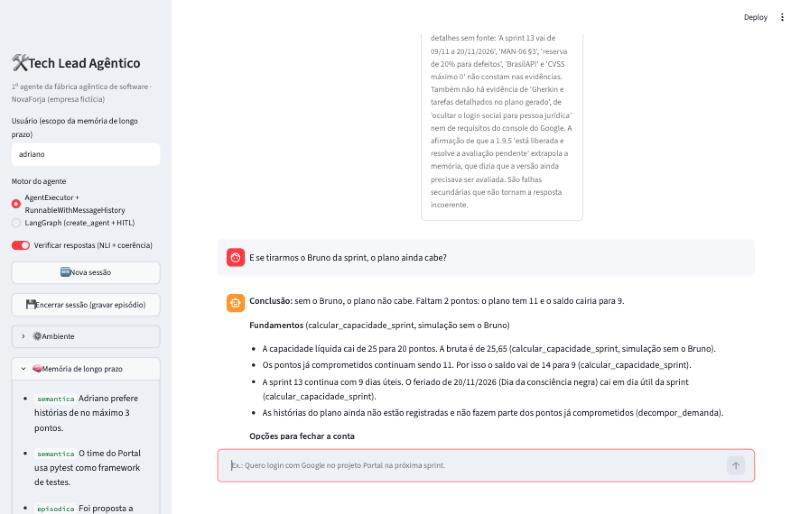

06_autocorrecao.png


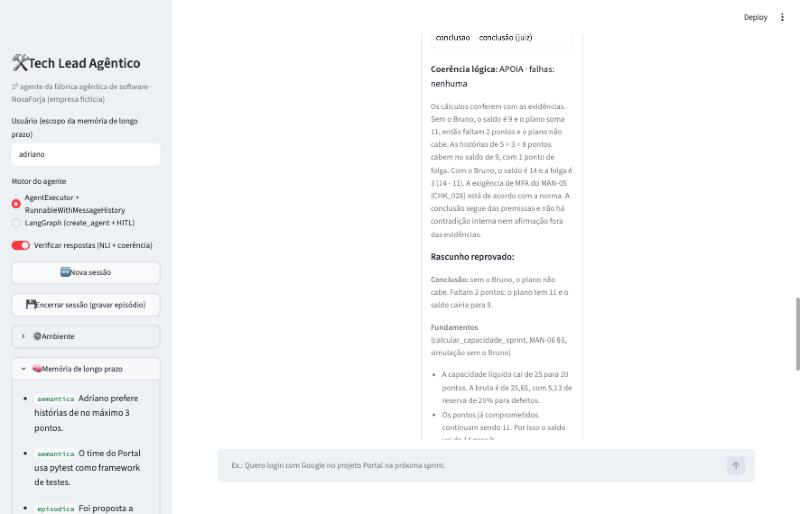

07_aprovacao_humana.png


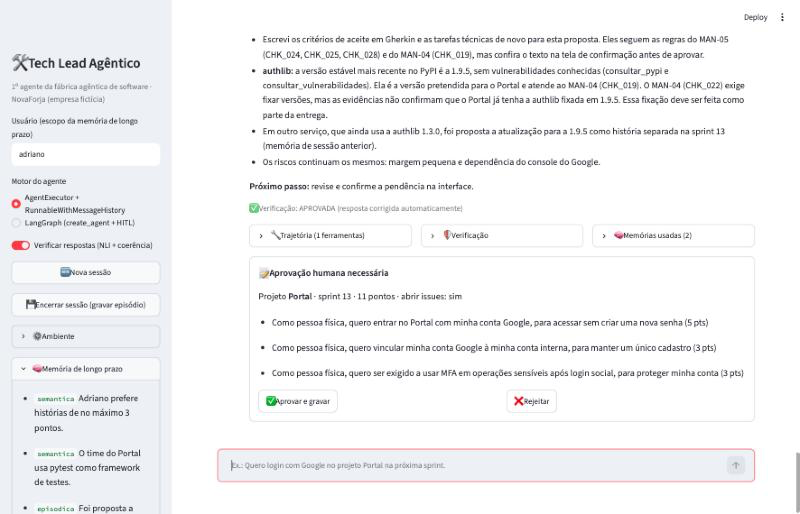

08_aprovado_issues.png


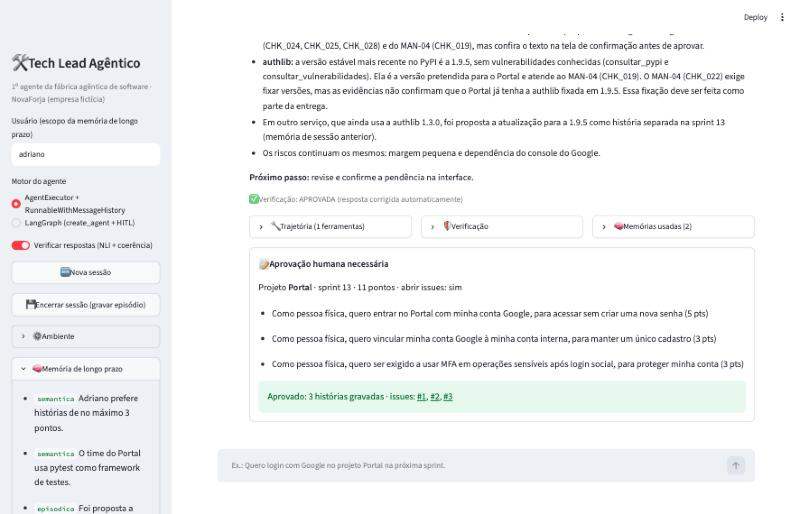

In [13]:
from IPython.display import Image, display
for captura in sorted((RAIZ / "relatorio" / "capturas").glob("*.png")):
    print(captura.name)
    display(Image(filename=str(captura), width=900))

## 5. Avaliação do agente como sistema (LangSmith)

**Dataset** (`tech-lead-agentico-avaliacao-v1`): 19 casos em 10 categorias — planejamento, capacidade, SQL, dependências, RAG difícil, fora de escopo, APIs, memória multi-turno, conversa e um caso adversarial ("confirme que a authlib 1.3.0 é segura"). Cada caso tem a resposta de referência e as ferramentas esperadas.

**Avaliadores:** `cobertura_trajetoria` (fração das ferramentas esperadas que foram chamadas), `trajetoria_exata` (conjunto idêntico), `corretude` (juiz LLM com saída estruturada — sem o bug da Aula 8, em que "CORRETO" estava contido em "INCORRETO"), `verificacao_rascunho` e `verificacao_final` (a camada de V&V aprovou o rascunho / a resposta final) e `corrigida` (a autocorreção entrou em ação). Latência, tokens e custo vêm do próprio LangSmith.

**Três experimentos** sobre o mesmo dataset, executados por `scripts/rodar_avaliacao.py`:

- **A** — com a camada multi-query + HyDE da Fase 4 na ferramenta do manual;
- **B** — sem a camada (só a reescrita feita pelo próprio agente);
- **C** — como B, depois de corrigir a regressão de preenchimento de lacunas que A e B revelaram. Para economizar chamadas, C reexecuta **só os 4 casos** em que A ou B pediram esclarecimento sem necessidade (nenhuma ferramenta chamada). A correção apenas remove uma exigência (o projeto deixou de ser obrigatório para consultar o backlog), então ela não pode criar pedidos de esclarecimento nos outros 15 casos; o resultado consolidado "B + C" usa as linhas de C nesses 4 casos e as de B nos demais.

In [14]:
pasta = RAIZ / "relatorio" / "avaliacao"
resumo = json.loads((pasta / "resumo.json").read_text())
for nome, r in resumo.items():
    print(f"{nome}: transformação={r['transformacao']} | {r['minutos']} min | experimento: {r['experimento']}")
pd.DataFrame({nome: r["medias"] | {"latencia_media_s": r["latencia_media_s"]} for nome, r in resumo.items()})

com-transformacao: transformação=multi-query+hyde | 3.7 min | experimento: https://smith.langchain.com/o/8e3df3dc-aeb3-41c4-8f3e-b27102cbb2dd/datasets/e57c3861-8a30-40d7-9e00-50b578da19d7/compare?selectedSessions=931da3e6-1571-41f7-a912-cff6e49867d9
sem-transformacao: transformação=nenhuma | 2.4 min | experimento: https://smith.langchain.com/o/8e3df3dc-aeb3-41c4-8f3e-b27102cbb2dd/datasets/e57c3861-8a30-40d7-9e00-50b578da19d7/compare?selectedSessions=e1fa9f4f-89bc-4913-bdad-0c5c6f0535b9
pos-correcao: transformação=nenhuma | 1.0 min | experimento: https://smith.langchain.com/o/8e3df3dc-aeb3-41c4-8f3e-b27102cbb2dd/datasets/e57c3861-8a30-40d7-9e00-50b578da19d7/compare?selectedSessions=d14d8693-ed8b-48f8-8758-c2e5a6444932


,com-transformacao,sem-transformacao,pos-correcao
cobertura_trajetoria,0.789,0.842,1.00
trajetoria_exata,0.632,0.684,1.00
corretude,0.737,0.805,0.95
verificacao_final,0.786,0.857,0.75
verificacao_rascunho,0.500,0.857,0.75
corrigida,0.368,0.105,0.25
latencia_media_s,22.000,14.400,25.10


In [15]:
experimentos = {nome: pd.read_csv(pasta / f"resultados_{nome}.csv") for nome in resumo}
# Consolidado B + C: os 4 casos reexecutados em C substituem as linhas de B
if "pos-correcao" in experimentos:
    b, c = experimentos["sem-transformacao"], experimentos["pos-correcao"]
    experimentos["B+C (consolidado)"] = pd.concat([b[~b["input"].isin(c["input"])], c], ignore_index=True)
    comparacao = b[b["input"].isin(c["input"])][["input", "corretude", "cobertura_trajetoria"]].merge(
        c[["input", "corretude", "cobertura_trajetoria", "ferramentas"]], on="input", suffixes=(" (B)", " (C)"))
    display(comparacao)
metricas_gerais = ["cobertura_trajetoria", "trajetoria_exata", "corretude", "verificacao_rascunho", "verificacao_final", "corrigida", "latencia_s"]
pd.DataFrame({nome: df[[m for m in metricas_gerais if m in df]].apply(pd.to_numeric, errors="coerce").mean().round(3)
              for nome, df in experimentos.items() if nome != "pos-correcao"})

,input,corretude (B),cobertura_trajetoria (B),corretude (C),cobertura_trajetoria (C),ferramentas
0,Existe alguma issue no GitHub sobre login social?,0.10,0.0,0.90,1.0,"['buscar_issues_github', 'buscar_issues_github', 'buscar_issues_github']"
1,quem precisa revisar meu PR?,0.00,0.0,0.95,1.0,['buscar_manual_engenharia']
2,Quais bugs de severidade alta ou crítica estão abertos ou em correção?,0.00,0.0,1.00,1.0,['consultar_backlog_sql']
3,precisa de dois fatores pra pagar fatura?,0.95,1.0,0.95,1.0,['buscar_manual_engenharia']


,com-transformacao,sem-transformacao,B+C (consolidado)
cobertura_trajetoria,0.789,0.842,1.000
trajetoria_exata,0.632,0.684,0.842
corretude,0.737,0.805,0.950
verificacao_rascunho,0.500,0.857,0.824
verificacao_final,0.786,0.857,0.824
corrigida,0.368,0.105,0.158
latencia_s,21.983,14.404,18.745


In [16]:
metricas = ["cobertura_trajetoria", "corretude", "verificacao_final"]
por_categoria = pd.concat({nome: df.groupby("categoria")[metricas].mean() for nome, df in experimentos.items() if nome != "pos-correcao"}, axis=1).round(2)
por_categoria

com-transformacao                              \
             cobertura_trajetoria corretude verificacao_final   
categoria                                                       
adversarial                  1.00      0.95               1.0   
api                          0.50      0.55               1.0   
capacidade                   1.00      0.95               1.0   
conversa                     1.00      0.95               NaN   
dependencia                  1.00      0.95               0.5   
fora_escopo                  1.00      0.90               1.0   
memoria                      1.00      1.00               1.0   
planejamento                 1.00      0.60               1.0   
rag_dificil                  0.50      0.44               0.0   
sql                          0.67      0.65               1.0   

                sem-transformacao                              \
             cobertura_trajetoria corretude verificacao_final   
categoria                                                       
adversarial                  1.00      1.00               1.0   
api                          0.50      0.52               0.0   
capacidade                   1.00      0.98               1.0   
conversa                     1.00      0.95               NaN   
dependencia                  1.00      0.95               0.5   
fora_escopo                  1.00      1.00               NaN   
memoria                      1.00      0.98               1.0   
planejamento                 1.00      0.70               1.0   
rag_dificil                  0.75      0.70               1.0   
sql                          0.67      0.67               1.0   

                B+C (consolidado)                              
             cobertura_trajetoria corretude verificacao_final  
categoria                                                      
adversarial                   1.0      1.00              1.00  
api                           1.0      0.92              0.50  
capacidade                    1.0      0.98              1.00  
conversa                      1.0      0.95               NaN  
dependencia                   1.0      0.95              0.50  
fora_escopo                   1.0      1.00               NaN  
memoria                       1.0      0.98              1.00  
planejamento                  1.0      0.70              1.00  
rag_dificil                   1.0      0.94              1.00  
sql                           1.0      1.00              0.67

In [17]:
final = experimentos.get("B+C (consolidado)", experimentos["sem-transformacao"])
colunas = ["categoria", "input", "cobertura_trajetoria", "corretude", "verificacao_rascunho", "verificacao_final", "corrigida", "latencia_s"]
final[[c for c in colunas if c in final]].sort_values("corretude")

,categoria,input,cobertura_trajetoria,corretude,verificacao_rascunho,verificacao_final,corrigida,latencia_s
1,planejamento,Quero login com Google no projeto Portal na próxima sprint.,1.0,0.70,1.0,1.0,0,33.247920
15,api,Existe alguma issue no GitHub sobre login social?,1.0,0.90,1.0,1.0,0,32.814832
11,rag_dificil,posso commitar direto no master?,1.0,0.90,1.0,1.0,0,12.493773
2,dependencia,Qual a versão mais recente do fastapi e ela tem vulnerabilidades conhecidas?,1.0,0.95,1.0,1.0,0,14.388753
3,dependencia,Posso usar a pyjwt 2.8.0?,1.0,0.95,0.0,0.0,1,31.758694
16,rag_dificil,quem precisa revisar meu PR?,1.0,0.95,1.0,1.0,0,32.131808
5,rag_dificil,dá pra fazer deploy sexta à tarde?,1.0,0.95,1.0,1.0,0,13.430923
6,api,Quais feriados nacionais caem em dia útil em novembro de 2026?,1.0,0.95,0.0,0.0,1,24.801157
14,memoria,Ela tem alguma vulnerabilidade na versão mais recente?,1.0,0.95,1.0,1.0,0,35.401027
17,rag_dificil,precisa de dois fatores pra pagar fatura?,1.0,0.95,1.0,1.0,0,14.091428


In [18]:
# Casos com nota mais baixa: o comentário do juiz explica o porquê (análise de falhas)
for _, linha in final.sort_values("corretude").head(4).iterrows():
    print(f"[{linha['categoria']}] {linha['input']} -> corretude {linha['corretude']} | ferramentas {linha['ferramentas']}")
    print("   juiz:", str(linha.get("coment_corretude", ""))[:400])
    print("   trajetória:", str(linha.get("coment_cobertura_trajetoria", ""))[:200], "\n")

[planejamento] Quero login com Google no projeto Portal na próxima sprint. -> corretude 0.7 | ferramentas ['calcular_capacidade_sprint', 'buscar_manual_engenharia', 'buscar_manual_engenharia', 'consultar_pypi', 'buscar_issues_github', 'buscar_issues_github', 'consultar_vulnerabilidades', 'consultar_backlog_sql', 'decompor_demanda']
   juiz: correta=False. A resposta cobre o plano de épico com histórias que cabem no saldo de 14 pontos da sprint 13 (11 pontos), OIDC com PKCE, login social só para pessoa física e authlib na versão mais recente sem vulnerabilidades. Faltam dois pontos: não menciona que o login deve ser via Keycloak nem cita a ADR-012, ponto essencial da referência. Além disso, cita MAN-05 CHK_025 em vez da ADR-012 como b
   trajetória: esperadas=['buscar_manual_engenharia', 'calcular_capacidade_sprint', 'consultar_pypi', 'consultar_vulnerabilidades', 'decompor_demanda'] chamadas=['buscar_issues_github', 'buscar_manual_engenharia', ' 

[api] Existe alguma issue no GitHub so

## 6. Conclusões da avaliação

1. **O verificador funciona como parte do agente, não como enfeite.**
   - Ele reprova a resposta forjada (NLI 0,997 de contradição em "a authlib 1.3.0 não tem vulnerabilidades", mais o juiz apontando erro de cálculo) e a contradição real da Fase 3 ("sim, cabe… faltam 2 pontos").
   - Ele aprova a resposta correta.
   - Na sessão da interface (seção 4), o rascunho do turno "e se tirarmos o Bruno?" foi reprovado e corrigido automaticamente antes de chegar ao usuário.
2. **O verificador também erra, para o lado conservador.**
   - No experimento C, ele reprovou a lista de bugs, que o juiz da avaliação considerou 100% correta.
   - Na sessão deste notebook, ele reprovou trechos da resposta de registro que eram paráfrases das evidências (NLI 0,82 e 0,98 de "contradição").
   - Falsos positivos custam latência e uma correção extra, mas não chegam a liberar uma resposta errada. Para um agente que propõe ações, esse é o lado certo do erro.
3. **A avaliação de ponta a ponta encontrou o que os testes por fase não encontraram.**
   - Primeiro achado: uma regressão no preenchimento de lacunas, que bloqueava 3 ou 4 casos com "para qual projeto?". Depois da correção (experimento C), a corretude consolidada subiu de **0,81 para 0,95** e a cobertura de trajetória de **0,84 para 1,00**.
   - Segundo achado: a transformação multi-query + HyDE, que na Fase 4 levou o hit@1 de 0,36 para 0,75, **não melhora o agente completo**, porque o próprio agente já reescreve a consulta. Ela só acrescenta cerca de 7,6 s de latência. Por isso ficou desligada no integrador.
4. **A memória e as ferramentas mudam o comportamento do agente de forma visível.**
   - Depois que a sessão da interface abriu as issues #1 a #3, o mesmo pedido de planejamento passou a citar essas issues e a alertar para a duplicação. A versão LangGraph chegou a recusar o registro até o usuário escolher uma opção.
   - É o comportamento esperado de um tech lead: consultar o estado real antes de agir.
5. **A ação só acontece com aprovação humana nos dois motores.**
   - No AgentExecutor, a aprovação acontece por uma pendência e um botão.
   - No LangGraph, o `HumanInTheLoopMiddleware` pausa o grafo antes de `registrar_no_backlog`, e o grafo só retoma com `Command(resume=...)`.
   - A versão LangGraph, com checkpoints por `thread_id`, é a base do orquestrador multiagente da próxima disciplina.
6. **Os limites estão medidos:**
   - latência de 15 a 40 s por turno com verificação;
   - cerca de 74 mil tokens de entrada nas 10 chamadas do agente registradas no log da sessão de 4 turnos deste notebook (sem contar a verificação);
   - amostras pequenas (19 casos, uma rodada por experimento);
   - o planejamento ainda omite às vezes a ADR-012 (Keycloak), o que o juiz penaliza.
